# Part 2 — Train the model and generate stories

In this notebook you will:

1. implement the training and evaluation loops,
2. train a baseline model,
3. generate stories with different sampling settings, and
4. visualize the attention weights.

Record your results and answers in [`report.md`](report.md).

A GPU is recommended. One training run of the baseline takes about
13 minutes on an NVIDIA RTX A4000 and uses about 2 GB of GPU memory with a
batch size of 64.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import matplotlib.pyplot as plt
import numpy as np
import torch
from tokenizers import Tokenizer

import assignment3 as a3

DATA_DIR = "./data"
OUTPUT_DIR = "./outputs"
SEED = 519
BATCH_SIZE = 64
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

tokenizer = Tokenizer.from_file(os.path.join(DATA_DIR, "tokenizer.json"))
vocab_size = tokenizer.get_vocab_size()
train_loader = a3.get_loader(DATA_DIR, "train", batch_size=BATCH_SIZE)
val_loader = a3.get_loader(DATA_DIR, "val", batch_size=BATCH_SIZE)
print("Training steps per epoch:", len(train_loader))

Device: cuda
Training steps per epoch: 7191


## 1. Training and evaluation loops

The training and evaluation loops are mostly the same as in Assignment 2, so
you can reuse a large part of your code.

We use the mean cross-entropy loss and the perplexity as metrics. The loss is
the average of $-\ln p$ over all positions, where $p$ is the probability that
the model gives to the correct next token. The **perplexity** is $e^\text{loss}$:
on average, the model gives the correct next token a probability of about
$1/\text{perplexity}$. For example, a model that gives all 4,096 tokens the same
probability has a perplexity of 4,096, and a perfect model has a perplexity of 1.

**Your task here:**

Complete `evaluate()` and `train_model()` in
[`assignment3/training.py`](assignment3/training.py) (1 mark each).

`evaluate()` should return the loss averaged over all windows, and the
perplexity. If `max_batches` is not `None`, only evaluate the first
`max_batches` batches.

`train_model()` should:

1. Create an AdamW optimizer with learning rate `1e-3` and weight decay `0.1`,
   and a OneCycleLR scheduler with `max_lr=1e-3`,
   `total_steps=num_epochs * len(train_loader)`, and `pct_start=0.05`. The
   scheduler increases the learning rate during the first 5% of the steps
   (warm-up) and then decreases it to almost 0.
2. For every mini-batch, run the forward pass, calculate the loss with
   `compute_loss()`, run backpropagation, clip the gradients with
   `torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)`, update the
   model, update the scheduler, and record the loss in `history`.
3. Every `eval_every` steps, evaluate the model on the first 50 validation
   batches with `evaluate()`, and record the step and the validation loss in
   `history`.

Notes:

1. As in Assignment 2, make proper use of `model.eval()`, `with torch.no_grad()`,
   and `model.train()`.
2. Move every mini-batch to `device` before the forward pass.
3. The last batch can be smaller than the others. Think carefully about how
   the mini-batch losses should be averaged.
4. Gradient clipping rescales the gradients when their norm is larger than 1,
   so that a single bad batch cannot change the weights too much.

Useful documentation:
- [Optimizing model parameters](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)
- [OneCycleLR](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.OneCycleLR.html)
- [`torch.nn.utils.clip_grad_norm_`](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.clip_grad_norm_.html)

The cells below check `evaluate()` on an untrained model, and train a small
model on 200 windows for a quick test of `train_model()`. The training loss
should decrease.

In [2]:
torch.manual_seed(SEED)
untrained_model = a3.GPT(vocab_size).to(device)
loss, perplexity = a3.evaluate(untrained_model, val_loader, device, max_batches=10)
print(f"Untrained model: loss {loss:.2f}, perplexity {perplexity:.0f}")

Untrained model: loss 8.47, perplexity 4780


In [3]:
torch.manual_seed(SEED)
small_model = a3.GPT(vocab_size, d_model=64, n_layers=2, n_heads=4).to(device)
small_dataset = torch.utils.data.Subset(train_loader.dataset, range(200))
small_loader = torch.utils.data.DataLoader(small_dataset, batch_size=8, shuffle=True)
small_history = a3.train_model(small_model, small_loader, small_loader, num_epochs=4, device=device,
                               eval_every=25)
print(f"Training loss: {small_history['train_loss'][0]:.2f} -> {small_history['train_loss'][-1]:.2f}")

Epoch 1/4, step 25/100: train loss 6.872, val loss 6.824
Epoch 2/4, step 50/100: train loss 6.177, val loss 6.015
Epoch 3/4, step 75/100: train loss 6.003, val loss 5.898
Epoch 4/4, step 100/100: train loss 5.988, val loss 5.887
Training loss: 8.47 -> 5.99


## 2. Train the baseline model (Question 1, 2 marks)

The baseline uses the default `GPT` settings (`d_model=256`, `n_layers=4`,
`n_heads=4`, `context_length=256`) and the training settings from Section 1
(1 epoch, learning rate `1e-3`, weight decay `0.1`).

The cell below trains the baseline and saves the model and its history in
`outputs/`. If the files already exist, it loads them instead; delete them if
you want to train the baseline again.

The plot shows the training loss averaged over the last 100 steps, and the validation
loss every 500 steps on the first 50 validation batches. The validation loss
printed above the plot is computed on the whole validation set.

In your report, include the validation loss and perplexity of the baseline
and the loss plot, and briefly describe the training and validation curves.

In [6]:
def train_or_load(name, model, num_epochs=1, **train_kwargs):
    # Train the model, or load it from outputs/ if it was trained before.
    model_path = os.path.join(OUTPUT_DIR, f"{name}.pt")
    history_path = os.path.join(OUTPUT_DIR, f"{name}_history.pt")
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    if os.path.exists(model_path):
        model.load_state_dict(torch.load(model_path, map_location=device))
        history = torch.load(history_path)
        print(f"Loaded {model_path}")
    else:
        history = a3.train_model(model, train_loader, val_loader, num_epochs, device, **train_kwargs)
        torch.save(model.state_dict(), model_path)
        torch.save(history, history_path)
    return history


def plot_history(histories, save_path=None):
    # Plot the training loss (averaged over the last 100 steps) and the validation loss of every model,
    # and save the figure to save_path if it is given.
    plt.figure(figsize=(7, 4))
    for name, history in histories.items():
        steps = np.arange(1, len(history["train_loss"]) + 1)
        train_loss = [np.mean(history["train_loss"][max(0, step - 100):step]) for step in steps]
        line, = plt.plot(steps, train_loss, label=f"{name} (train)")
        plt.plot(history["val_step"], history["val_loss"], "o--", color=line.get_color(), label=f"{name} (val)")
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.ylim(1, 9)
    plt.legend()
    plt.grid(alpha=0.25)
    if save_path is not None:
        plt.savefig(save_path)
    plt.show()

Parameters: 5,326,336
Epoch 1/1, step 500/7191: train loss 3.020, val loss 3.088
Epoch 1/1, step 1000/7191: train loss 2.556, val loss 2.507
Epoch 1/1, step 1500/7191: train loss 2.236, val loss 2.263
Epoch 1/1, step 2000/7191: train loss 2.158, val loss 2.118
Epoch 1/1, step 2500/7191: train loss 1.976, val loss 2.030
Epoch 1/1, step 3000/7191: train loss 1.970, val loss 1.966
Epoch 1/1, step 3500/7191: train loss 1.927, val loss 1.914
Epoch 1/1, step 4000/7191: train loss 1.877, val loss 1.874
Epoch 1/1, step 4500/7191: train loss 1.822, val loss 1.842
Epoch 1/1, step 5000/7191: train loss 1.846, val loss 1.814
Epoch 1/1, step 5500/7191: train loss 1.749, val loss 1.792
Epoch 1/1, step 6000/7191: train loss 1.801, val loss 1.777
Epoch 1/1, step 6500/7191: train loss 1.739, val loss 1.768
Epoch 1/1, step 7000/7191: train loss 1.699, val loss 1.765
Baseline validation loss: 1.761, perplexity: 5.82


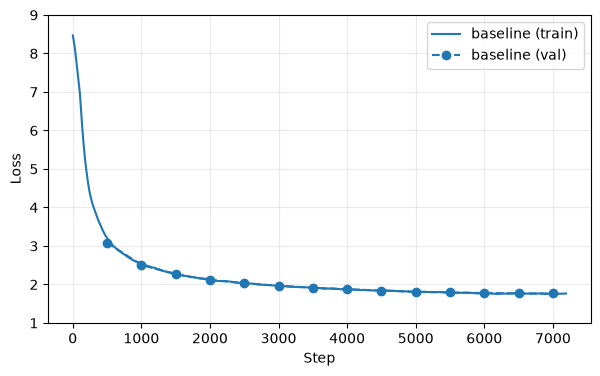

In [5]:
torch.manual_seed(SEED)
baseline_model = a3.GPT(vocab_size).to(device)
print(f"Parameters: {sum(p.numel() for p in baseline_model.parameters()):,}")
baseline_history = train_or_load("baseline", baseline_model)

baseline_loss, baseline_perplexity = a3.evaluate(baseline_model, val_loader, device)
print(f"Baseline validation loss: {baseline_loss:.3f}, perplexity: {baseline_perplexity:.2f}")
plot_history({"baseline": baseline_history}, save_path="assets/baseline_loss.png")

## 3. Generate stories (Question 2, 2 marks)

The function below generates a story from a prompt with `GPT.generate()` and
stops at the first `<|endoftext|>`. The cell below generates stories with
different temperatures, with and without top-k. You can change the settings, the
prompt, or `generation_seed` to generate more stories.

In your report, use these stories as examples to describe what 1. the
temperature and 2. top-k do to the generated stories, and explain why.

In [7]:
def generate_story(model, prompt, temperature=1.0, top_k=None, num_new_tokens=200):
    # Generate a continuation of the prompt and return the text up to the end of the story.
    model.eval()
    ids = torch.tensor([tokenizer.encode(prompt).ids], device=device)
    out = model.generate(ids, num_new_tokens, temperature=temperature, top_k=top_k)
    text = tokenizer.decode(out[0].tolist(), skip_special_tokens=False)
    return text.split("<|endoftext|>")[0]


prompt = "Once upon a time"
generation_seed = 0  # change it to generate different stories
sampling_results = []
for temperature, top_k in [(0.5, None), (1.0, None), (1.5, None), (1.5, 50)]:
    torch.manual_seed(generation_seed)
    story = generate_story(baseline_model, prompt, temperature, top_k)
    sampling_results.append({"temperature": temperature, "top_k": top_k, "story": story})
    print(f"----- temperature {temperature}, top-k {top_k}")
    print(story)
    print()

----- temperature 0.5, top-k None
Once upon a time, there was a little girl named Lily. She loved to play with her toys. One day, she found a big, red ball. She thought it would be fun to play with.
Lily took the ball to her friend Tom. Tom was a little scared, but he wanted to play with the ball. So, he said, "Let's play with the ball!" Lily was happy and said, "Yes, let's play!"
They played with the ball and had lots of fun. But then, something unexpected happened. The ball started to move and dance! It was not a ball at all, but a big, friendly dog. The dog saw the ball and wanted to play with it too.
Lily and Tom were very surprised. They did not know that the dog could talk. The dog was very friendly and wanted to play too. The dog and the dog played with the ball and had lots of fun. They were happy they had a new friend to play with.

----- temperature 1.0, top-k None
Once upon a time, there was a soldier. He was a small soldier. He liked to go on walks and be a big, strong sold

## 4. Visualize the attention (Question 3, 2 marks)

Every `AttentionHead` saves its attention weights in `attention_weights` during the forward pass, so we can plot the attention map for visualization. 

The cell below plots the attention weights that are used to generate each new token. In each plot, the y-axis shows the token being predicted, the x-axis shows the tokens it looks at, and a darker color means a larger weight.

**Your task here:**

Write a short sentence and let the model continue it with a few tokens.

In your report, choose one example and describe whether the attention plots show any patterns.

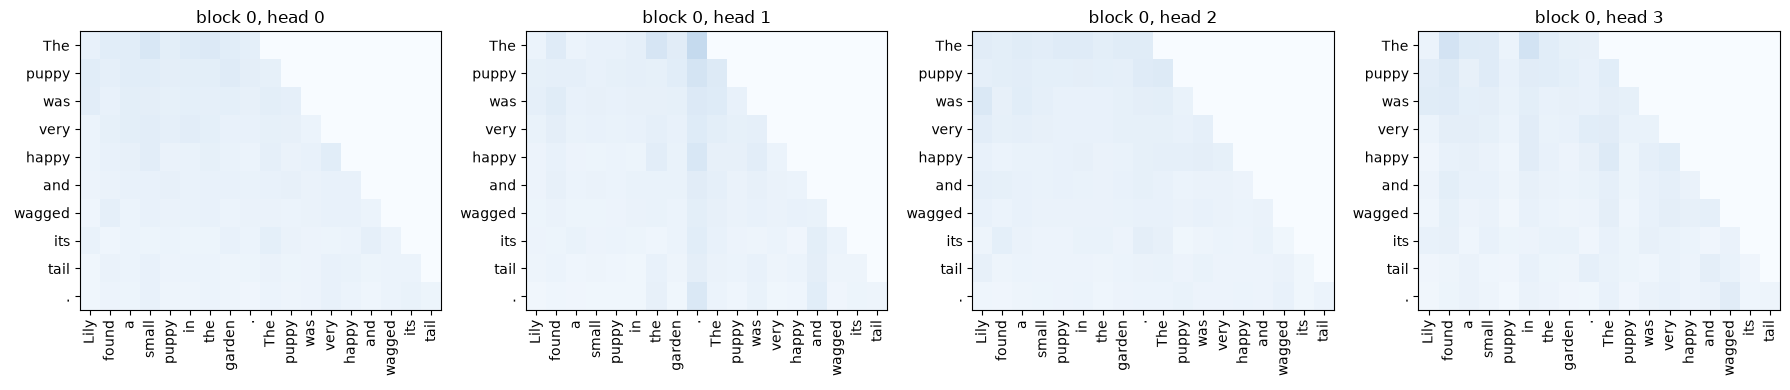

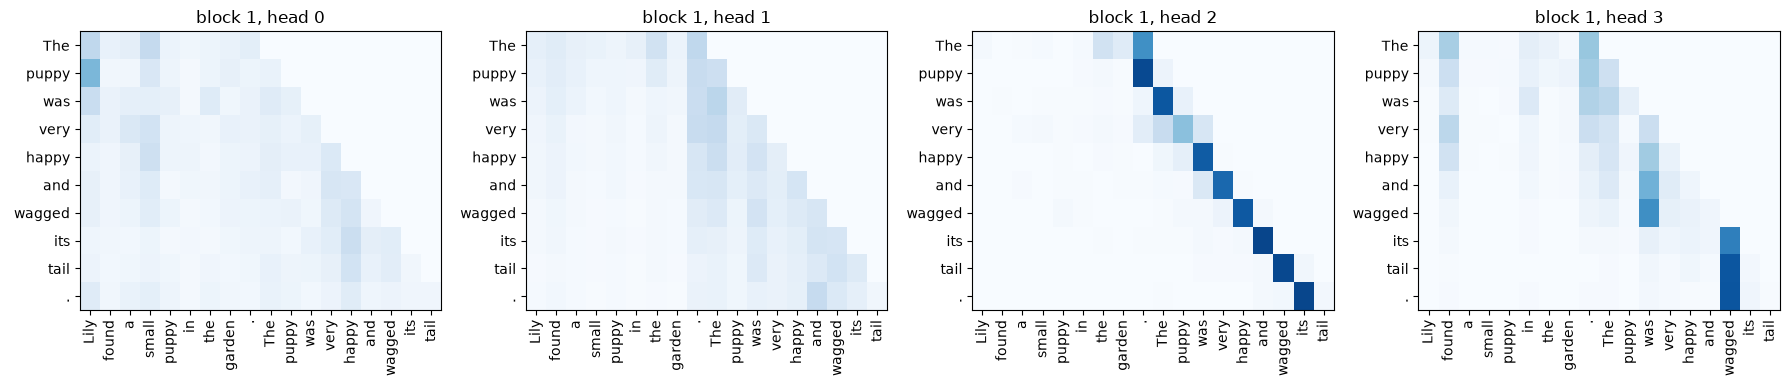

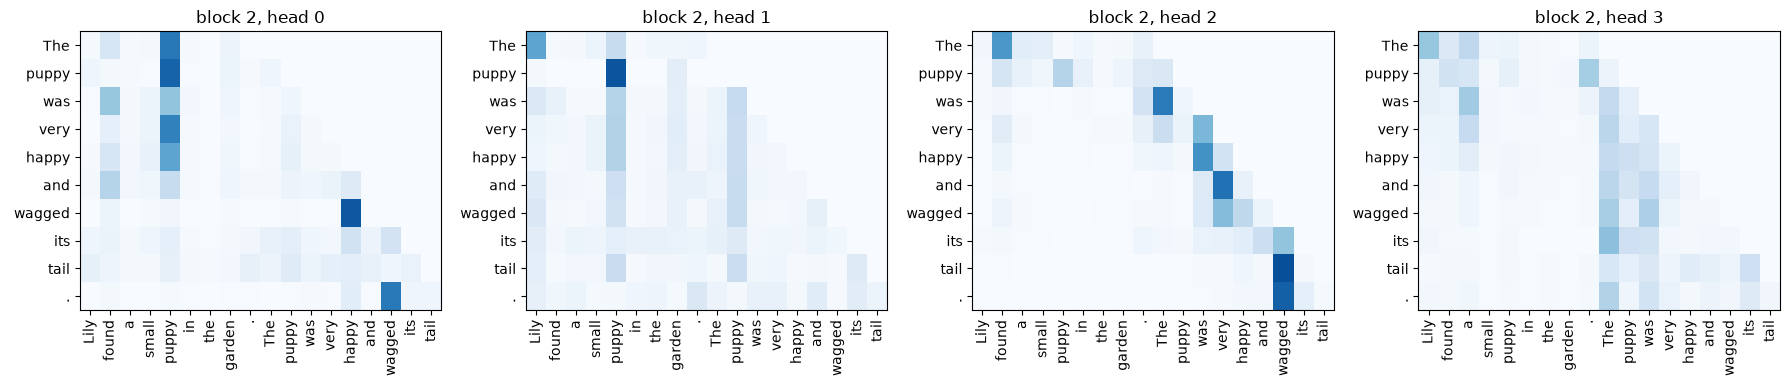

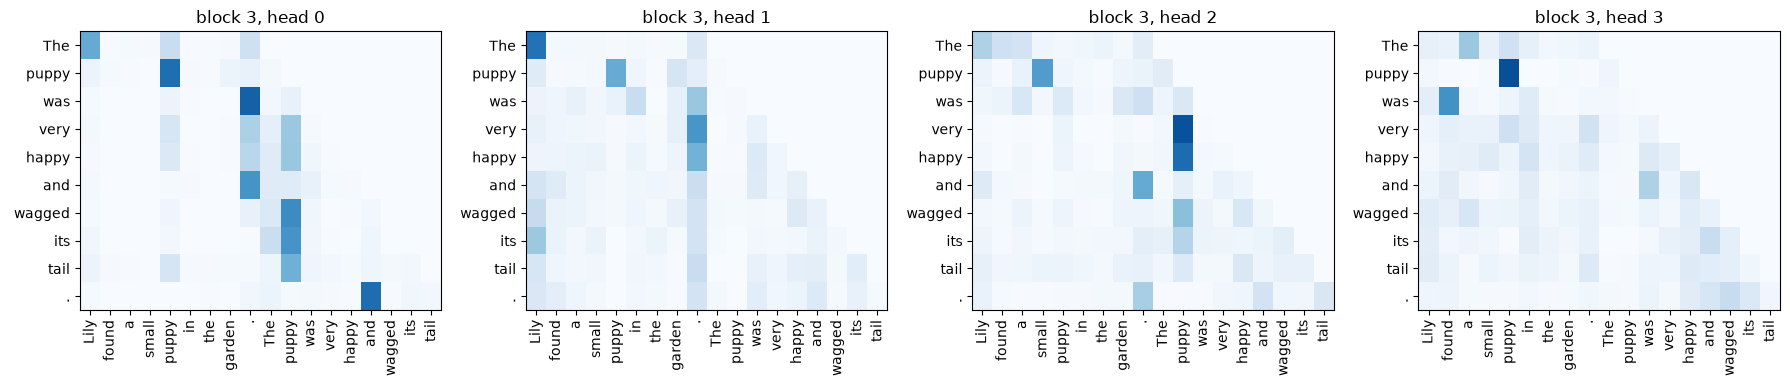

In [8]:
def plot_attention(model, prompt, block_index, num_new_tokens=10, save_path=None):
    # Continue the prompt with num_new_tokens tokens (always the most likely token), and show
    # the attention weights of all heads in one block that were used to predict each new token.
    model.eval()
    prompt_ids = torch.tensor([tokenizer.encode(prompt).ids], device=device)
    ids = model.generate(prompt_ids, num_new_tokens, top_k=1)
    tokens = [tokenizer.id_to_token(i).replace("Ġ", " ").replace("Ċ", "\\n") for i in ids[0].tolist()]
    with torch.no_grad():
        model(ids[:, :-1])  # the last token is not used to predict anything
    first_row = prompt_ids.shape[1] - 1  # the row that predicts the first new token
    new_tokens = tokens[first_row + 1:]
    heads = model.blocks[block_index].attention.heads
    fig, axes = plt.subplots(1, len(heads), figsize=(4.5 * len(heads), 4))
    for h, (head, ax) in enumerate(zip(heads, axes)):
        ax.imshow(head.attention_weights[0, first_row:].cpu(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(len(tokens) - 1), tokens[:-1], rotation=90)
        ax.set_yticks(range(len(new_tokens)), new_tokens)
        ax.set_title(f"block {block_index}, head {h}")
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path)
    plt.show()


####################################
# Your implementation starts here. #
####################################
prompt = "Lily found a small puppy in the garden."
##################################
# Your implementation ends here. #
##################################
num_new_tokens = 10
for block_index in range(len(baseline_model.blocks)):
    plot_attention(baseline_model, prompt, block_index, num_new_tokens,
                   save_path=f"assets/attention_block{block_index}.png")